# Homework 1
## Multi-Armed Bandit
This is a 10 arm bandit problem. The 10 arm bandits set their mean values using a normal distribution of mean 0 and variance 1. For each action, the bandits give a reward with a mean equal to the true action value that was sampled from a normal distribution and a variance of 1. Possible actions are 0 to 9.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
class Bandit:
    def __init__(self):
        self.mean_values = [np.random.normal(loc=0, scale=1) for _ in range(10)]

    def reward(self, action):
        return np.random.normal(loc=self.mean_values[action], scale=1)

## Part 1: Strategies

In [7]:
def greedy(bandit, T=1000):
    Q = np.zeros(10)
    N = np.zeros(10)
    rewards = np.zeros(T)
    optimal = np.zeros(T)
    best_action = np.argmax(bandit.mean_values)

    for t in range(T):
        action = np.argmax(Q)
        r = bandit.reward(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards[t] = r
        optimal[t] = 1 if action == best_action else 0

    return rewards, optimal

In [8]:
def epsilon_greedy_constant(bandit, T=1000, epsilon=0.2):
    Q = np.zeros(10)
    N = np.zeros(10)
    rewards = np.zeros(T)
    optimal = np.zeros(T)
    best_action = np.argmax(bandit.mean_values)

    for t in range(T):
        if np.random.random() < epsilon:
            action = np.random.randint(10)
        else:
            action = np.argmax(Q)
        r = bandit.reward(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards[t] = r
        optimal[t] = 1 if action == best_action else 0

    return rewards, optimal

In [9]:
def epsilon_greedy_linear_decay(bandit, T=1000, epsilon0=0.2, epsilon_min=0.01):
    Q = np.zeros(10)
    N = np.zeros(10)
    rewards = np.zeros(T)
    optimal = np.zeros(T)
    best_action = np.argmax(bandit.mean_values)
    k = (epsilon0 - epsilon_min) / T

    for t in range(T):
        epsilon = max(0, epsilon0 - k * t)
        if np.random.random() < epsilon:
            action = np.random.randint(10)
        else:
            action = np.argmax(Q)
        r = bandit.reward(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards[t] = r
        optimal[t] = 1 if action == best_action else 0

    return rewards, optimal

In [10]:
def epsilon_greedy_exp_decay(bandit, T=1000, epsilon0=0.2, epsilon_min=0.01):
    Q = np.zeros(10)
    N = np.zeros(10)
    rewards = np.zeros(T)
    optimal = np.zeros(T)
    best_action = np.argmax(bandit.mean_values)
    alpha = np.exp(np.log(epsilon_min / epsilon0) / T)

    for t in range(T):
        epsilon = epsilon0 * (alpha ** t)
        if np.random.random() < epsilon:
            action = np.random.randint(10)
        else:
            action = np.argmax(Q)
        r = bandit.reward(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards[t] = r
        optimal[t] = 1 if action == best_action else 0

    return rewards, optimal

In [11]:
def epsilon_greedy_optimistic(bandit, T=1000, Q0=5.0):
    Q = np.full(10, Q0, dtype=float)
    N = np.zeros(10)
    rewards = np.zeros(T)
    optimal = np.zeros(T)
    best_action = np.argmax(bandit.mean_values)

    for t in range(T):
        action = np.argmax(Q)
        r = bandit.reward(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards[t] = r
        optimal[t] = 1 if action == best_action else 0

    return rewards, optimal

In [12]:
def ucb(bandit, T=1000, c=2):
    Q = np.zeros(10)
    N = np.zeros(10)
    rewards = np.zeros(T)
    optimal = np.zeros(T)
    best_action = np.argmax(bandit.mean_values)

    for t in range(T):
        if t < 10:
            action = t
        else:
            ucb_values = Q + c * np.sqrt(np.log(t + 1) / N)
            action = np.argmax(ucb_values)
        r = bandit.reward(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards[t] = r
        optimal[t] = 1 if action == best_action else 0

    return rewards, optimal

In [13]:
def thompson_sampling(bandit, T=1000):
    mu = np.zeros(10)
    sigma = np.ones(10)
    N = np.zeros(10)
    sum_r = np.zeros(10)
    rewards = np.zeros(T)
    optimal = np.zeros(T)
    best_action = np.argmax(bandit.mean_values)

    for t in range(T):
        samples = np.random.normal(mu, sigma)
        action = np.argmax(samples)
        r = bandit.reward(action)
        N[action] += 1
        sum_r[action] += r
        mu[action] = sum_r[action] / N[action]
        sigma[action] = 1.0 / np.sqrt(N[action])
        rewards[t] = r
        optimal[t] = 1 if action == best_action else 0

    return rewards, optimal

## Part 2: Experiment Setup

We run each strategy on 100 independent bandits for 1000 time steps each and average the results.

In [14]:
num_bandits = 100
T = 1000

strategies = {
    'Greedy': greedy,
    'Epsilon-Greedy (constant)': epsilon_greedy_constant,
    'Epsilon-Greedy (linear decay)': epsilon_greedy_linear_decay,
    'Epsilon-Greedy (exp decay)': epsilon_greedy_exp_decay,
    'Optimistic Init': epsilon_greedy_optimistic,
    'UCB': ucb,
    'Thompson Sampling': thompson_sampling,
}

all_rewards = {name: np.zeros((num_bandits, T)) for name in strategies}
all_optimal = {name: np.zeros((num_bandits, T)) for name in strategies}

for i in range(num_bandits):
    b = Bandit()
    for name, fn in strategies.items():
        r, o = fn(b)
        all_rewards[name][i] = r
        all_optimal[name][i] = o

mean_rewards = {name: all_rewards[name].mean(axis=0) for name in strategies}
std_rewards  = {name: all_rewards[name].std(axis=0) / np.sqrt(num_bandits) for name in strategies}

mean_optimal = {name: all_optimal[name].mean(axis=0) * 100 for name in strategies}
std_optimal  = {name: all_optimal[name].std(axis=0) / np.sqrt(num_bandits) * 100 for name in strategies}

## Part 3: Results and Analysis

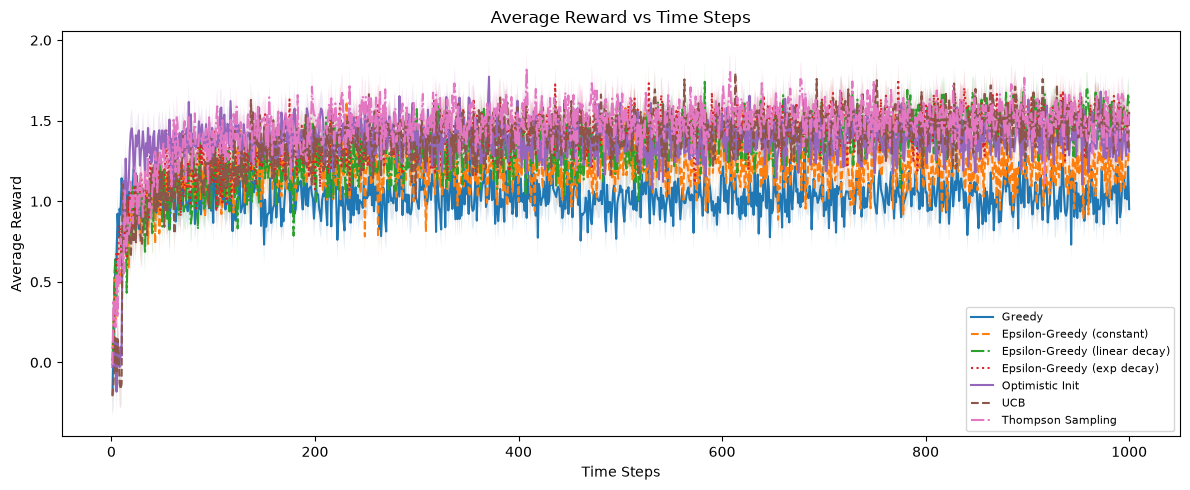

In [15]:
steps = np.arange(1, T + 1)
linestyles = ['-', '--', '-.', ':', '-', '--', '-.']

plt.figure(figsize=(12, 5))
for (name, mean), ls in zip(mean_rewards.items(), linestyles):
    se = std_rewards[name]
    plt.plot(steps, mean, label=name, linestyle=ls)
    plt.fill_between(steps, mean - se, mean + se, alpha=0.15)

plt.xlabel('Time Steps')
plt.ylabel('Average Reward')
plt.title('Average Reward vs Time Steps')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

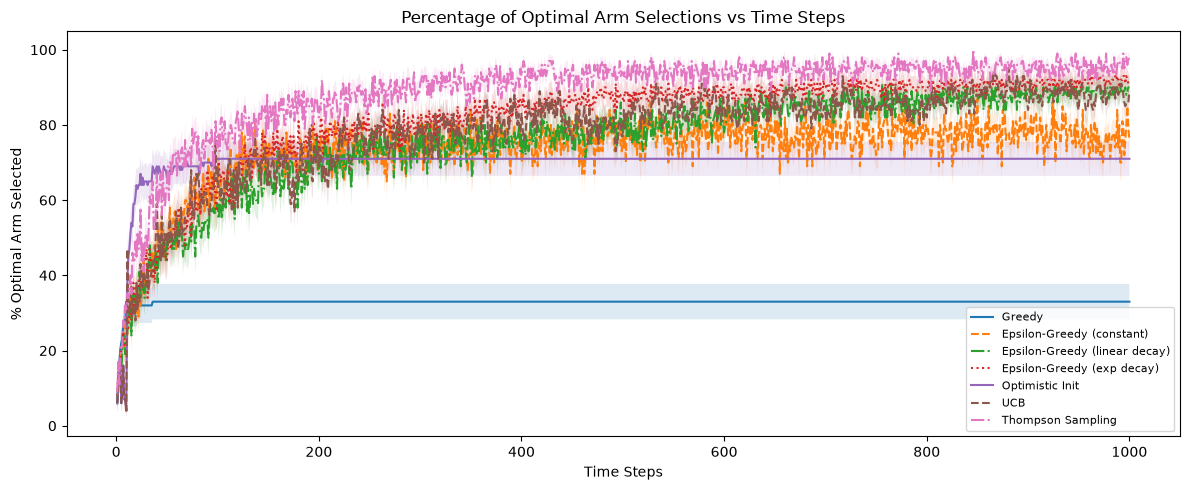

In [16]:
plt.figure(figsize=(12, 5))
for (name, mean), ls in zip(mean_optimal.items(), linestyles):
    se = std_optimal[name]
    plt.plot(steps, mean, label=name, linestyle=ls)
    plt.fill_between(steps, mean - se, mean + se, alpha=0.15)

plt.xlabel('Time Steps')
plt.ylabel('% Optimal Arm Selected')
plt.title('Percentage of Optimal Arm Selections vs Time Steps')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Discussion

**Exploration speed.** Thompson Sampling and UCB identify the best arm fastest. They explore in a smart, targeted way rather than randomly, so they start pulling the best arm much sooner than the simpler epsilon-greedy methods.

**Long-term reward.** Thompson Sampling achieves the highest average reward in the long run. UCB comes in close second. Among the epsilon-greedy variants, exponential decay does the best because it explores a lot early on and then shifts almost entirely to exploitation by the end. Constant epsilon keeps exploring at a fixed rate even when it no longer needs to, which hurts its long-term reward.

**Greedy.** Pure greedy often gets stuck on a suboptimal arm because it has no way to recover once it has committed to a wrong choice. It shows the worst long-term performance.

**Optimistic initialization.** Starting with high Q values forces the agent to try every arm at least once early on, which gives it a reasonable initial picture of the environment. After that initial phase it behaves like greedy, so it can still get stuck if those early samples were noisy.

**Variance.** Thompson Sampling and UCB have relatively low variance across runs because their exploration is guided. Constant epsilon-greedy has the highest variance since it keeps making random choices throughout.

**Key trade-off.** More exploration early leads to better long-term performance but lower reward in the first few hundred steps. Greedy gets decent reward early but pays for it later. Exponential decay and Thompson Sampling strike the best balance between the two.